In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"C:\Users\usaan\Downloads\data_science_datasets\netflix_content.csv")

In [3]:
df.head()

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type
0,The Night Agent: Season 1,Yes,2023-03-23,"81,21,00,000",English,Show
1,Ginny & Georgia: Season 2,Yes,2023-01-05,"66,51,00,000",English,Show
2,The Glory: Season 1 // 더 글로리: 시즌 1,Yes,2022-12-30,"62,28,00,000",Korean,Show
3,Wednesday: Season 1,Yes,2022-11-23,"50,77,00,000",English,Show
4,Queen Charlotte: A Bridgerton Story,Yes,2023-05-04,"50,30,00,000",English,Movie


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24812 entries, 0 to 24811
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Title                24812 non-null  object
 1   Available Globally?  24812 non-null  object
 2   Release Date         8166 non-null   object
 3   Hours Viewed         24812 non-null  object
 4   Language Indicator   24812 non-null  object
 5   Content Type         24812 non-null  object
dtypes: object(6)
memory usage: 1.1+ MB


In [5]:
df.shape

(24812, 6)

In [6]:
df.columns

Index(['Title', 'Available Globally?', 'Release Date', 'Hours Viewed',
       'Language Indicator', 'Content Type'],
      dtype='object')

In [7]:
# Data Preprocessing

In [8]:
df.isnull().sum()

Title                      0
Available Globally?        0
Release Date           16646
Hours Viewed               0
Language Indicator         0
Content Type               0
dtype: int64

In [9]:
df.duplicated().sum()

467

In [10]:
df[df.duplicated()]

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type
18646,Seinfeld: Season 4,Yes,NaN,"4,28,00,000",English,Show
18678,Friends (1994): Season 10,No,NaN,"3,22,00,000",English,Show
18694,The InBESTigators: Season 1,Yes,2019-08-09,"2,02,00,000",English,Show
19027,Safe: Season 1,Yes,2018-05-10,"1,65,00,000",English,Show
19080,LEGO City 2018,No,NaN,"10,00,000",English,Movie
...,...,...,...,...,...,...
24806,W. Kamau Bell: Private School Negro,Yes,2018-06-26,"1,00,000",English,Movie
24808,Whitney Cummings: Can I Touch It?,Yes,2019-07-30,"1,00,000",English,Movie
24809,Whitney Cummings: Jokes,No,2022-07-26,"1,00,000",English,Movie
24810,"Whose Vote Counts, Explained: Limited Series",Yes,2020-09-28,"1,00,000",English,Movie


In [11]:
df["Language Indicator"].value_counts()

Language Indicator
English        17268
Non-English     3252
Japanese        2297
Korean          1582
Hindi            374
Russian           39
Name: count, dtype: int64

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df.duplicated().sum()

0

In [14]:
df["Release Date"] = pd.to_datetime(df["Release Date"],errors="coerce")

In [15]:
df["Release Date"].isnull().sum()

16370

In [16]:
df["Hours Viewed"]=df["Hours Viewed"].str.replace(',','').astype('int64')

In [17]:
df["Hours Viewed"].head()

0    812100000
1    665100000
2    622800000
3    507700000
4    503000000
Name: Hours Viewed, dtype: int64

In [18]:
df["Available Globally?"].unique()

array(['Yes', 'No'], dtype=object)

In [19]:
df["Language Indicator"].unique()

array(['English', 'Korean', 'Non-English', 'Japanese', 'Hindi', 'Russian'],
      dtype=object)

In [20]:
df["Content Type"].unique()

array(['Show', 'Movie'], dtype=object)

In [21]:
df["Available Globally?"]=df["Available Globally?"].map({"Yes":0,"No":1})

In [22]:
df["Language_ID"]=df["Language Indicator"].map({"English":0,"Korean":1,"Non-English":2,"Japanese":3,"Hindi":4,"Russian":5})

In [23]:
df["Content_Type_ID"]=df["Content Type"].map({"Show":0,"Movie":1})

In [24]:
df.head()

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type,Language_ID,Content_Type_ID
0,The Night Agent: Season 1,0,2023-03-23,812100000,English,Show,0,0
1,Ginny & Georgia: Season 2,0,2023-01-05,665100000,English,Show,0,0
2,The Glory: Season 1 // 더 글로리: 시즌 1,0,2022-12-30,622800000,Korean,Show,1,0
3,Wednesday: Season 1,0,2022-11-23,507700000,English,Show,0,0
4,Queen Charlotte: A Bridgerton Story,0,2023-05-04,503000000,English,Movie,0,1


In [25]:
df.dropna(subset=['Title'], inplace=True)
df.drop_duplicates(subset=['Title'], inplace=True)

In [26]:
# Reset index after removing duplicates and missing titles

df.reset_index(drop=True, inplace=True)

# Reassign continuous Content IDs

df["Content_ID"] = np.arange(
    len(df),
    dtype=np.int32
)

In [27]:
df.head()

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type,Language_ID,Content_Type_ID,Content_ID
0,The Night Agent: Season 1,0,2023-03-23,812100000,English,Show,0,0,0
1,Ginny & Georgia: Season 2,0,2023-01-05,665100000,English,Show,0,0,1
2,The Glory: Season 1 // 더 글로리: 시즌 1,0,2022-12-30,622800000,Korean,Show,1,0,2
3,Wednesday: Season 1,0,2022-11-23,507700000,English,Show,0,0,3
4,Queen Charlotte: A Bridgerton Story,0,2023-05-04,503000000,English,Movie,0,1,4


In [28]:
# EDA

In [29]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.describe())

(19158, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Title                19158 non-null  object        
 1   Available Globally?  19158 non-null  int64         
 2   Release Date         5118 non-null   datetime64[ns]
 3   Hours Viewed         19158 non-null  int64         
 4   Language Indicator   19158 non-null  object        
 5   Content Type         19158 non-null  object        
 6   Language_ID          19158 non-null  int64         
 7   Content_Type_ID      19158 non-null  int64         
 8   Content_ID           19158 non-null  int32         
dtypes: datetime64[ns](1), int32(1), int64(4), object(3)
memory usage: 1.2+ MB
None
Title                      0
Available Globally?        0
Release Date           14040
Hours Viewed               0
Language Indicator         0
Content Type             

In [30]:
df['Content Type'].value_counts()

Content Type
Movie    12702
Show      6456
Name: count, dtype: int64

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

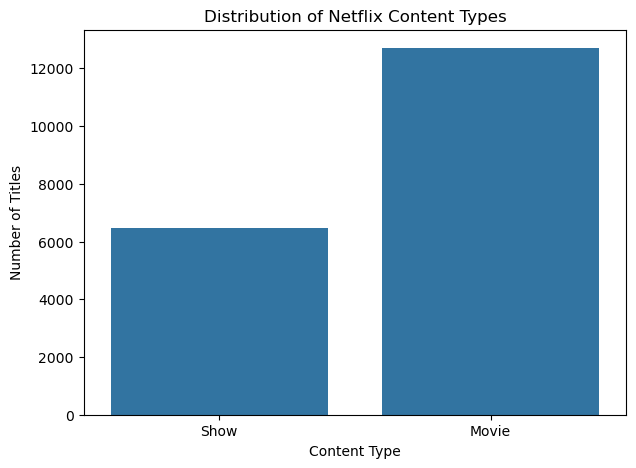

In [32]:
plt.figure(figsize=(7,5))
sns.countplot(df,x=df["Content Type"])
plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

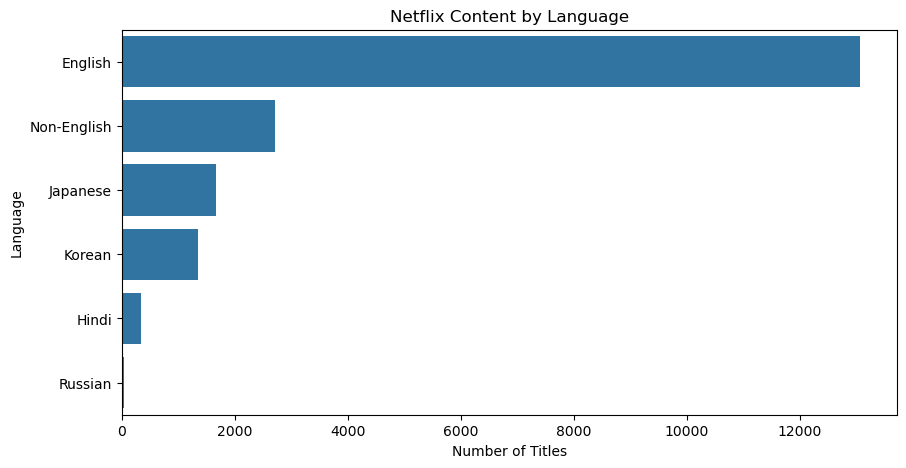

In [33]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df,y='Language Indicator',order=df['Language Indicator'].value_counts().index)
plt.title('Netflix Content by Language')
plt.xlabel('Number of Titles')
plt.ylabel('Language')
plt.show()

In [34]:
top_10=df.sort_values(by='Hours Viewed',ascending=False).head()

In [35]:
top_10

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type,Language_ID,Content_Type_ID,Content_ID
0,The Night Agent: Season 1,0,2023-03-23,812100000,English,Show,0,0,0
1,Ginny & Georgia: Season 2,0,2023-01-05,665100000,English,Show,0,0,1
2,The Glory: Season 1 // 더 글로리: 시즌 1,0,2022-12-30,622800000,Korean,Show,1,0,2
18214,ONE PIECE: Season 1,0,2023-08-31,541900000,English,Show,0,0,18214
3,Wednesday: Season 1,0,2022-11-23,507700000,English,Show,0,0,3


C:\Users\usaan\anaconda3\envs\tf_amd\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 45908 (\N{HANGUL SYLLABLE DEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\usaan\anaconda3\envs\tf_amd\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 44544 (\N{HANGUL SYLLABLE GEUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\usaan\anaconda3\envs\tf_amd\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\usaan\anaconda3\envs\tf_amd\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\usaan\anaconda3\envs\tf_amd\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing 

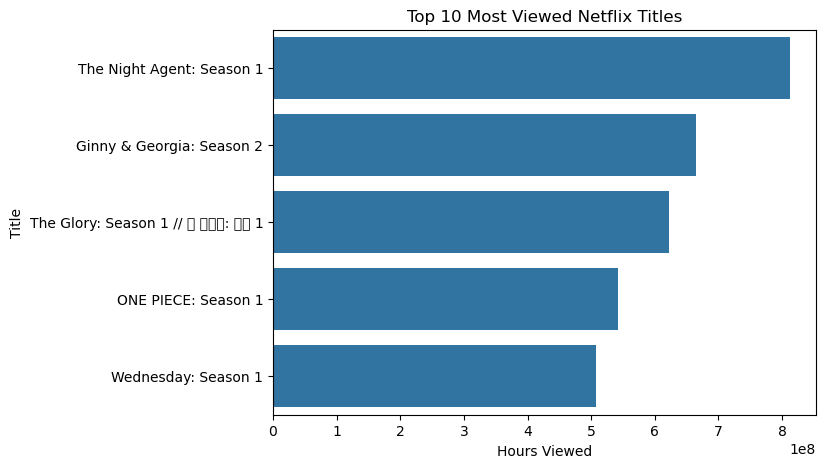

In [36]:
plt.figure(figsize=(7,5))
sns.barplot(data=top_10,x="Hours Viewed",y="Title")
plt.title("Top 10 Most Viewed Netflix Titles")
plt.xlabel("Hours Viewed")
plt.ylabel("Title")
plt.show()

In [37]:
#Build a Neural Recommendation Model Using TensorFlow

In [38]:
import tensorflow as tf
from tensorflow.keras import layers,Model

In [39]:
num_content=df["Content_ID"].nunique()

In [40]:
num_languages=df["Language_ID"].nunique()

In [41]:
num_types=df["Content_Type_ID"].nunique()

In [42]:
content_input = layers.Input(shape=(1,), dtype=tf.int32, name='content_id')
language_input = layers.Input(shape=(1,), dtype=tf.int32, name='language_id')
type_input = layers.Input(shape=(1,), dtype=tf.int32, name='content_type')

In [43]:
content_embedding=layers.Embedding(input_dim=num_content+1,output_dim=32)(content_input)
language_embedding=layers.Embedding(input_dim=num_languages+1,output_dim=8)(language_input)
type_embedding=layers.Embedding(input_dim=num_types+1,output_dim=4)(type_input)

In [44]:
content_vec=layers.Flatten()(content_embedding)
language_vec=layers.Flatten()(language_embedding)
type_vec=layers.Flatten()(type_embedding)

In [45]:
combined=layers.concatenate([content_vec,language_vec,type_vec])
x=layers.Dense(64,activation="relu")(combined)
x=layers.Dense(32,activation="relu")(x)
output = layers.Dense(num_content,activation="softmax")(x)

In [46]:
model=Model(inputs=[content_input,language_input,type_input],outputs=output)

In [47]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [48]:
history=model.fit(
    x={'content_id':df["Content_ID"],'language_id':df["Language_ID"],'content_type':df["Content_Type_ID"]},
    y=df["Content_ID"],
    epochs=5,
    batch_size=64)

Epoch 1/5
300/300 [==============================] - 14s 44ms/step - loss: 9.9127 - accuracy: 0.0000e+00
Epoch 2/5
300/300 [==============================] - 13s 45ms/step - loss: 9.8682 - accuracy: 0.0000e+00
Epoch 3/5
300/300 [==============================] - 36s 119ms/step - loss: 9.5651 - accuracy: 1.0440e-04
Epoch 4/5
300/300 [==============================] - 82s 272ms/step - loss: 8.0526 - accuracy: 0.0064
Epoch 5/5
300/300 [==============================] - 81s 272ms/step - loss: 6.0739 - accuracy: 0.0872


In [51]:
model.save("Netflix_Recommendation.keras")

In [53]:
df.to_pickle("netflix_data.pkl")
print("Model and dataset saved successfully!")

Model and dataset saved successfully!


In [49]:
def recommend_similar(content_title,top_k=5):
    content_row=df[df["Title"].str.contains(content_title,case=False,na=False)].iloc[0]
    content_id=content_row["Content_ID"]
    language_id=content_row["Language_ID"]
    content_type_id=content_row["Content_Type_ID"]

    predictions=model.predict(x={
        'content_id':np.array([content_id]),
        'language_id':np.array([language_id]),
        'content_type':np.array([content_type_id])
    })

    top_indices=predictions[0].argsort()[-top_k-1:][::-1]
    recommendations= df[df["Content_ID"].isin(top_indices)]

    return recommendations[['Title', 'Language Indicator', 'Content Type', 'Hours Viewed']]
      


In [50]:
recommend_similar("Friends")

1/1 [==============================] - 0s 138ms/step


,Title,Language Indicator,Content Type,Hours Viewed
2616,Black Lightning: Season 3,English,Show,7500000
5199,Final Space: Season 3,English,Show,2600000
5894,Down to Earth with Zac Efron: Season 1,English,Show,2000000
6521,Fatma: Season 1,English,Show,1600000
7068,Yizo Yizo: Season 2,English,Show,1400000
12963,Exposed: The Case Of Keli Lane: Season 1,English,Show,200000
